# Рівень 3. Дообучення передобученої моделі (ResNet-18, ImageNet)

**Задача:** та сама, що на рівнях 1 і 2: за ASCII-рисунком визначити об'єкт (10 класів).
**Метод рівня 3:** transfer learning. Беремо згорткову мережу **ResNet-18**, яку вже навчили на наборі **ImageNet** (≈ 1.28 млн фотографій, 1000 класів), і **дообучаємо** (fine-tuning) її на наших рисунках.

**Чому саме так.** Висновки рівня 2 показали, що обмеження — не в задачі, а в кількості даних: мережа, навчена з нуля на 938 прикладах, швидко запам'ятовує train і перенавчається. Передобучена мережа вже вміє знаходити на зображеннях лінії, кути, дуги, текстури й частини об'єктів. Ці загальні знання не потрібно вчити з нуля з наших 938 рисунків, їх достатньо підлаштувати під ASCII-арт.

**Що залишається тим самим** (щоб порівняння було чесним):
- ті самі 1341 рисунок і **те саме розбиття** train / val / test з `splits.csv`;
- ті самі метрики (macro-F1 як основна, accuracy), той самий спосіб вимірювання часу і пам'яті;
- та сама функція `render()` (текст → зображення), що на рівнях 1 і 2.

**Залізо.** Як і рівень 2, фінальний запуск зроблено в Google Colab на GPU. Залізо кожного рівня вказано в порівняльній таблиці.

План:
1. Дані та розбиття
2. Що таке передобучена модель і fine-tuning
3. Підготовка зображень і аугментація
4. Три варіанти навчання
5. Вибір моделі та фінальна оцінка на test
6. Порівняння всіх трьох рівнів
7. Висновки

> **Як запустити.** У Google Colab: Runtime → Change runtime type → GPU, потім Runtime → Run all; повний прогін триває кілька хвилин. На CPU ноутбука він тривав би понад годину, тому для цього рівня GPU фактично обов'язковий. При першому запуску torchvision завантажує ваги ResNet-18 (≈ 45 MB).

## 1. Дані та розбиття

Якщо ноутбук запущено в Google Colab, спочатку завантажуємо репозиторій з датасетом і `splits.csv` з GitHub. Локально цей крок пропускається.

In [20]:
import os
import subprocess
import sys

if 'google.colab' in sys.modules:
    if not os.path.exists('/content/ML'):
        subprocess.run(['git', 'clone', '-q', 'https://github.com/seibtoy/ML.git', '/content/ML'], check=True)
    os.chdir('/content/ML/level3')
print('Робоча папка:', os.getcwd())

Робоча папка: /content/ML/level3


In [21]:
import copy
import json
import platform
import threading
import time

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from PIL import Image, ImageDraw, ImageFont
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, f1_score

SEED = 42
DATASET_DIR = '../dataset'
SPLITS_PATH = '../splits.csv'
IMAGE_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 20

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


def cpu_name():
    if sys.platform == 'darwin':
        return subprocess.run(['sysctl', '-n', 'machdep.cpu.brand_string'], capture_output=True, text=True).stdout.strip()
    with open('/proc/cpuinfo') as f:
        return next(line.split(':', 1)[1].strip() for line in f if line.startswith('model name'))


hardware = f'GPU {torch.cuda.get_device_name(0)}' if device.type == 'cuda' else f'CPU {cpu_name()}'
print('Залізо:', hardware)
print('Python', platform.python_version())
for module in [torch, torchvision, np, pd, matplotlib, psutil]:
    print(module.__name__, module.__version__)
print('scikit-learn', __import__('sklearn').__version__, '| pillow', Image.__version__)

Залізо: GPU Tesla T4
Python 3.13.16
torch 2.11.0+cu130
torchvision 0.26.0+cu130
numpy 2.4.6
pandas 2.2.3
matplotlib 3.10.0
psutil 5.9.5
scikit-learn 1.6.1 | pillow 11.3.0


In [22]:
splits = pd.read_csv(SPLITS_PATH)
texts = [open(os.path.join(DATASET_DIR, f), encoding='utf-8').read() for f in splits['file']]
classes = sorted(splits['label'].unique())
labels = splits['label'].map({c: i for i, c in enumerate(classes)}).to_numpy()

parts = {name: np.flatnonzero(splits['split'] == name) for name in ['train', 'val', 'test']}
y = {name: labels[idx] for name, idx in parts.items()}
{name: len(idx) for name, idx in parts.items()}

{'train': 938, 'val': 201, 'test': 202}

Клас `Measure` — той самий, що на рівні 2: час виконання блоку коду, пікова RAM процесу і пікова VRAM (пам'ять GPU). Перед зупинкою таймера чекаємо, поки GPU завершить усі обчислення (`torch.cuda.synchronize()`), інакше час був би заниженим.

In [23]:
class Measure:
    def __enter__(self):
        self.process = psutil.Process()
        self.peak_rss = self.process.memory_info().rss
        self.running = True
        self.sampler = threading.Thread(target=self.sample, daemon=True)
        self.sampler.start()
        if device.type == 'cuda':
            torch.cuda.synchronize()
            torch.cuda.reset_peak_memory_stats()
        self.started = time.perf_counter()
        return self

    def sample(self):
        while self.running:
            self.peak_rss = max(self.peak_rss, self.process.memory_info().rss)
            time.sleep(0.005)

    def __exit__(self, *exc):
        if device.type == 'cuda':
            torch.cuda.synchronize()
        self.seconds = time.perf_counter() - self.started
        self.running = False
        self.sampler.join()
        self.peak_rss = max(self.peak_rss, self.process.memory_info().rss)
        self.peak_mb = self.peak_rss / 2**20
        self.peak_vram_mb = torch.cuda.max_memory_allocated() / 2**20 if device.type == 'cuda' else None

## 2. Що таке передобучена модель і fine-tuning

### ResNet-18

**ResNet-18** — згорткова нейромережа, яку запропонували дослідники Microsoft у 2015 році. Вона побудована з тих самих «цеглин», що й мережа рівня 2 (згортки, BatchNorm, ReLU, pooling, лінійний шар), але значно більша:
- **18 шарів з вагами** (17 згорткових і 1 лінійний) замість 3 згорткових на рівні 2;
- **≈ 11.7 млн ваг** замість ≈ 0.1 млн, тобто приблизно у 115 разів більше;
- **залишкові з'єднання (residual connections)**: кожен блок не замінює свій вхід, а додає до нього поправку (`x + F(x)`). Сигнал і градієнт можуть проходити «в обхід» блоків, тому таку глибоку мережу вдається навчити.

### Передобучення на ImageNet

**ImageNet** — набір з ≈ 1.28 млн фотографій 1000 класів, серед яких багато порід котів і собак, птахи, літаки, човни, автомобілі, будівлі. На ньому ResNet-18 навчали кілька днів на кількох GPU. Готові ваги опубліковані в бібліотеці `torchvision` (`IMAGENET1K_V1`), і ми їх просто завантажуємо.

Що вміють шари передобученої мережі:
- **перші шари** знаходять краї, штрихи, кути (як HOG на рівні 1, але вивчене);
- **середні** — текстури та візерунки з цих штрихів;
- **глибокі** — частини об'єктів: очі, вуха, колеса, крила.

ASCII-рисунки — не фотографії, але на них намальовані ті самі об'єкти, і їхні контури складаються з тих самих штрихів і дуг. Тому знання з ImageNet мають бути корисними.

### Як пристосовуємо мережу до нашої задачі

Останній шар ResNet-18 (`fc`) рахує 1000 оцінок для класів ImageNet. Ми **замінюємо його новим лінійним шаром на 10 класів** (512 × 10 + 10 = 5 130 ваг) з випадковими початковими вагами. Далі є три варіанти навчання, і ми порівнюємо всі три:

1. **Заморожена мережа (feature extraction).** Ваги ResNet не змінюються, навчається лише новий останній шар. Мережа працює як готовий екстрактор ознак (ніби HOG з рівня 1, але вивчений на ImageNet), а останній шар — як логістична регресія над цими ознаками.
2. **Та сама ResNet-18 з випадковими вагами** (без передобучення). Це контрольний експеримент: він показує, що дає саме передобучення, а що — просто більша і сучасніша архітектура.
3. **Повний fine-tuning.** Починаємо з ваг ImageNet і дообучаємо **всі** 11.7 млн ваг. Learning rate невеликий, щоб підлаштувати знання мережі під ASCII-арт, а не стерти їх.

Процедура навчання (батчі по 32, AdamW, One-Cycle, вибір найкращої епохи за val macro-F1) — та сама, що на рівні 2.

In [24]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


class ResNetClassifier(nn.Module):
    def __init__(self, pretrained, freeze_backbone):
        super().__init__()
        weights = torchvision.models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        self.backbone = torchvision.models.resnet18(weights=weights)
        self.backbone.fc = nn.Linear(self.backbone.fc.in_features, len(classes))
        self.freeze_backbone = freeze_backbone
        if freeze_backbone:
            for name, parameter in self.backbone.named_parameters():
                parameter.requires_grad = name.startswith('fc.')
        self.register_buffer('mean', torch.tensor(IMAGENET_MEAN).view(1, 3, 1, 1))
        self.register_buffer('std', torch.tensor(IMAGENET_STD).view(1, 3, 1, 1))

    def train(self, mode=True):
        super().train(mode)
        if self.freeze_backbone:
            for module in self.backbone.modules():
                if isinstance(module, nn.BatchNorm2d):
                    module.eval()
        return self

    def forward(self, x):
        x = ((1 - x).repeat(1, 3, 1, 1) - self.mean) / self.std
        return self.backbone(x)


def count_parameters(model, trainable_only=False):
    return sum(p.numel() for p in model.parameters() if p.requires_grad or not trainable_only)

Кілька деталей у коді:
- **Вхід.** ResNet очікує кольорове зображення, нормалізоване середнім і стандартним відхиленням ImageNet. Наш рисунок сірий, тому ми повторюємо його канал тричі (R = G = B), перетворюємо на чорні символи на білому тлі (як папір) і нормалізуємо. Це робиться всередині `forward()`, тож мережа приймає ті самі зображення, що й на рівні 2.
- **Заморожування.** У замороженому варіанті `requires_grad = False` для всіх ваг, крім останнього шару, тому оптимізатор їх не змінює. Крім того, шари BatchNorm залишаються в режимі оцінки: інакше вони під час навчання оновлювали б свою статистику, і «заморожена» мережа все одно змінювалась би.

In [25]:
def predict_logits(model, x):
    model.eval()
    with torch.no_grad():
        return torch.cat([model(x[i:i + 128].to(device)) for i in range(0, len(x), 128)])


def train(model, x_train, x_val, epochs, lr, augment=None):
    model.to(device)
    x_train, x_val = x_train.to(device), x_val.to(device)
    generator = torch.Generator().manual_seed(SEED)
    counts = np.bincount(y['train'], minlength=len(classes))
    class_weights = torch.tensor(len(y['train']) / (len(classes) * counts), dtype=torch.float32, device=device)
    loss_fn = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=lr, total_steps=epochs, pct_start=0.15)
    y_train, y_val = torch.from_numpy(y['train']).to(device), torch.from_numpy(y['val']).to(device)

    history, best_f1, best_state = [], -1, None
    for epoch in range(epochs):
        model.train()
        order = torch.randperm(len(x_train), generator=generator).to(device)
        train_loss, train_pred = 0.0, torch.empty(len(x_train), dtype=torch.long, device=device)
        for start in range(0, len(order), BATCH_SIZE):
            batch = order[start:start + BATCH_SIZE]
            xb = augment(x_train[batch], generator) if augment else x_train[batch]
            logits = model(xb)
            loss = loss_fn(logits, y_train[batch])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * len(batch)
            train_pred[batch] = logits.argmax(1)
        scheduler.step()

        val_logits = predict_logits(model, x_val)
        val_f1 = f1_score(y['val'], val_logits.argmax(1).cpu().numpy(), average='macro')
        history.append({
            'epoch': epoch + 1,
            'train loss': train_loss / len(x_train),
            'val loss': loss_fn(val_logits, y_val).item(),
            'train macro-F1': f1_score(y['train'], train_pred.cpu().numpy(), average='macro'),
            'val macro-F1': val_f1,
        })
        if val_f1 > best_f1:
            best_f1, best_state = val_f1, copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    return pd.DataFrame(history)


def plot_history(history, title):
    best = history.loc[history['val macro-F1'].idxmax()]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    history.plot(x='epoch', y=['train loss', 'val loss'], ax=axes[0], title='Loss (менше — краще)')
    history.plot(x='epoch', y=['train macro-F1', 'val macro-F1'], ax=axes[1], title='Macro-F1 (більше — краще)')
    for ax in axes:
        ax.axvline(best['epoch'], color='gray', linestyle='--', linewidth=1)
    fig.suptitle(f"{title}: найкраща епоха {int(best['epoch'])}, val macro-F1 = {best['val macro-F1']:.3f}")
    plt.tight_layout()
    plt.show()

Функції `train()`, `predict_logits()` і `plot_history()` скопійовано з рівня 2 з однією зміною: оптимізатор отримує лише ті ваги, які навчаються (`requires_grad`), щоб у замороженому варіанті не обробляти 11 млн ваг, які не змінюються.

## 3. Підготовка зображень і аугментація

Рисунки рендеряться тією самою функцією `render()`, що на рівнях 1 і 2, але в розмірі **224×224** — це стандартний розмір входу ResNet, і на ньому в символів удвічі більше пікселів, ніж на 128×128 у рівні 2.

**Аугментація** (лише для train, на кожному батчі заново) — випадкові зміни, після яких об'єкт залишається тим самим:
- **віддзеркалення** по горизонталі з імовірністю 50%. Тут віддзеркалюються пікселі, тож `/` автоматично стає `\` (на рівні 2 для сітки символів це доводилося робити таблицею заміни);
- **масштаб** від 0.9 до 1.1;
- **зсув** до 10% розміру зображення по кожній осі.

Усе це одне афінне перетворення, яке PyTorch застосовує одразу до всього батчу (`affine_grid` + `grid_sample`), тому аугментація працює на GPU і майже не уповільнює навчання.

In [26]:
FONT = ImageFont.truetype(os.path.join(matplotlib.get_data_path(), 'fonts/ttf/DejaVuSansMono.ttf'), 16)
CHAR_WIDTH = FONT.getlength('M')
LINE_HEIGHT = 19
MARGIN = 8


def render(text, size=IMAGE_SIZE):
    lines = text.rstrip('\n').split('\n')
    width = int(np.ceil(max(len(line) for line in lines) * CHAR_WIDTH))
    height = len(lines) * LINE_HEIGHT
    side = max(width, height) + 2 * MARGIN
    canvas = Image.new('L', (side, side), 255)
    draw = ImageDraw.Draw(canvas)
    left, top = (side - width) // 2, (side - height) // 2
    for i, line in enumerate(lines):
        draw.text((left, top + i * LINE_HEIGHT), line, fill=0, font=FONT)
    canvas = canvas.resize((size, size), Image.Resampling.LANCZOS)
    return 1 - np.asarray(canvas, dtype=np.float32) / 255


def to_images(texts):
    return torch.from_numpy(np.stack([render(t) for t in texts])).unsqueeze(1)


def augment_images(x, generator):
    n = len(x)
    flip = torch.where(torch.rand(n, generator=generator) < 0.5, -1.0, 1.0)
    scale = 0.9 + 0.2 * torch.rand(n, generator=generator)
    shift = 0.4 * (torch.rand(n, 2, generator=generator) - 0.5)
    theta = torch.zeros(n, 2, 3)
    theta[:, 0, 0] = flip / scale
    theta[:, 1, 1] = 1 / scale
    theta[:, :, 2] = shift
    grid = F.affine_grid(theta.to(x.device), list(x.shape), align_corners=False)
    return F.grid_sample(x, grid, padding_mode='zeros', align_corners=False)

{'train': (938, 1, 224, 224), 'val': (201, 1, 224, 224), 'test': (202, 1, 224, 224)}


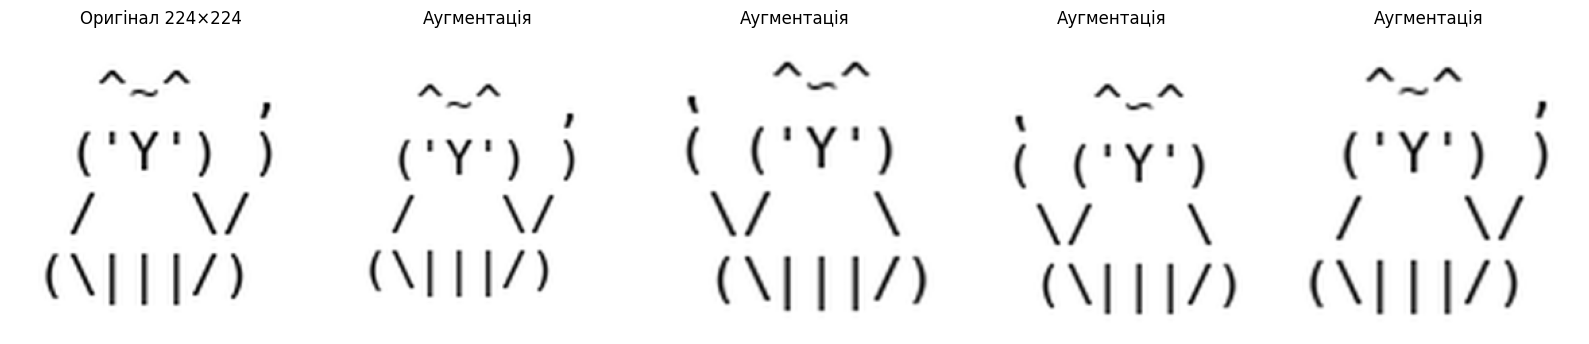

In [27]:
images, image_prep_cost = {}, {}
for name, idx in parts.items():
    with Measure() as m:
        images[name] = to_images([texts[i] for i in idx])
    image_prep_cost[name] = m
print({name: tuple(x.shape) for name, x in images.items()})

sample = images['train'][[i for i in range(len(y['train'])) if classes[y['train'][i]] == 'cat'][5]][None]
fig, axes = plt.subplots(1, 5, figsize=(16, 3.6))
axes[0].imshow(sample[0, 0], cmap='gray_r')
axes[0].set_title(f'Оригінал {IMAGE_SIZE}×{IMAGE_SIZE}')
augmented = augment_images(sample.repeat(4, 1, 1, 1), torch.Generator().manual_seed(1))
for ax, image in zip(axes[1:], augmented):
    ax.imshow(image[0], cmap='gray_r')
    ax.set_title('Аугментація')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

## 4. Три варіанти навчання

Усі три варіанти отримують однаковий бюджет: **20 епох** з тією самою аугментацією. Різняться лише початкові ваги, те, які ваги навчаються, і learning rate:

| Варіант | Початкові ваги | Що навчається | Learning rate |
|---|---|---|---|
| Спроба 1 | ImageNet | лише останній шар | 3e-3 |
| Спроба 2 | випадкові | уся мережа | 1e-3 |
| Спроба 3 | ImageNet | уся мережа | 1e-3 |

Для замороженої мережі learning rate більший, бо навчається лише один новий шар з випадковими вагами. Для всієї мережі він менший, щоб великі кроки не зруйнували корисні ваги ImageNet.

In [28]:
def fit_attempt(title, pretrained, freeze_backbone, lr):
    torch.manual_seed(SEED)
    model = ResNetClassifier(pretrained, freeze_backbone)
    print(f'{title}: ваг у мережі {count_parameters(model):,}, з них навчаються {count_parameters(model, trainable_only=True):,}')
    with Measure() as fit_cost:
        history = train(model, images['train'], images['val'], epochs=EPOCHS, lr=lr, augment=augment_images)
    print(f'Навчання: {fit_cost.seconds / 60:.1f} хв, пік RAM {fit_cost.peak_mb:.0f} MB, пік VRAM {fit_cost.peak_vram_mb} MB')
    plot_history(history, title)
    return model, history, fit_cost

### Спроба 1: заморожена ResNet-18, навчається лише останній шар

Спроба 1: заморожена ResNet-18: ваг у мережі 11,181,642, з них навчаються 5,130
Навчання: 0.4 хв, пік RAM 2092 MB, пік VRAM 1450.99755859375 MB


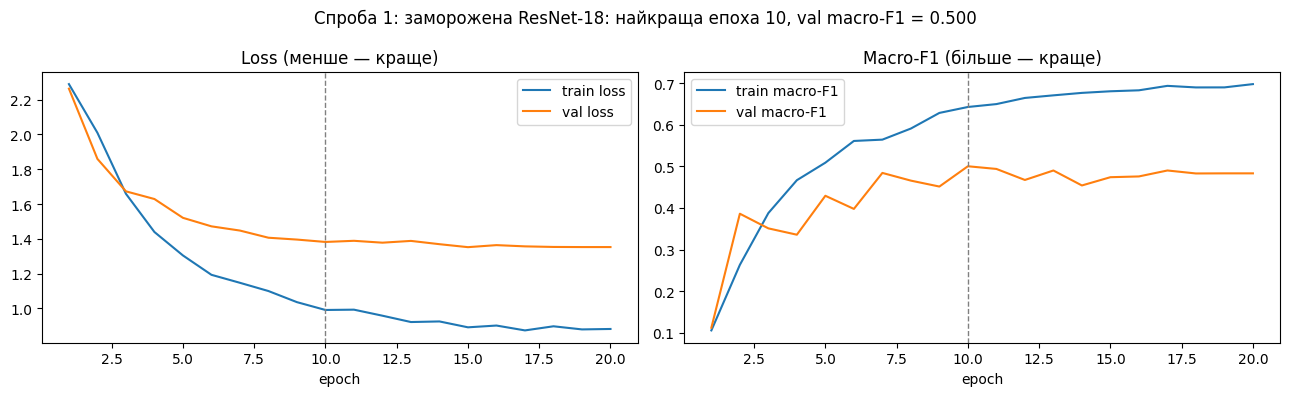

In [29]:
frozen = fit_attempt('Спроба 1: заморожена ResNet-18', pretrained=True, freeze_backbone=True, lr=3e-3)

### Спроба 2: ResNet-18 з випадковими вагами (без передобучення)

Спроба 2: ResNet-18 з нуля: ваг у мережі 11,181,642, з них навчаються 11,181,642
Навчання: 1.1 хв, пік RAM 2093 MB, пік VRAM 1624.22412109375 MB


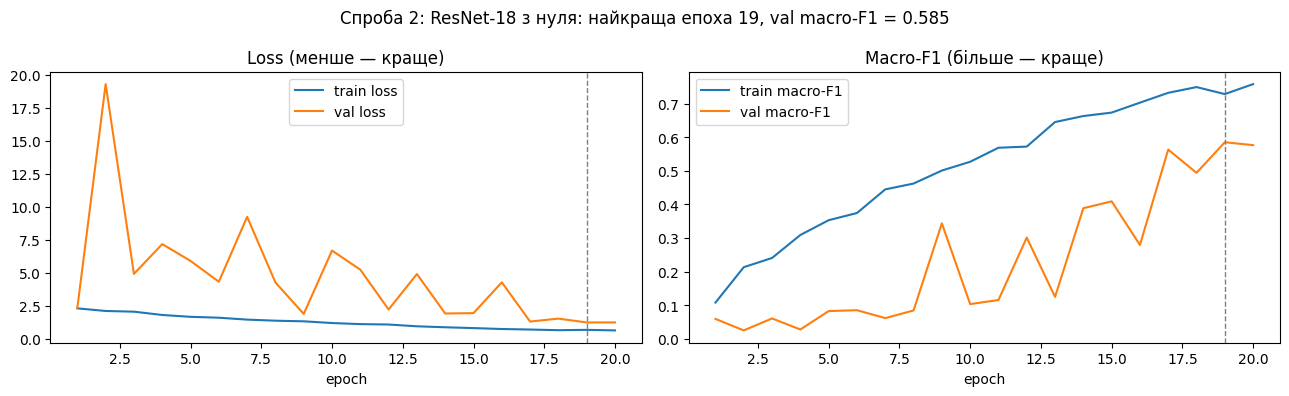

In [30]:
scratch = fit_attempt('Спроба 2: ResNet-18 з нуля', pretrained=False, freeze_backbone=False, lr=1e-3)

### Спроба 3: повний fine-tuning ResNet-18

Спроба 3: fine-tuning ResNet-18: ваг у мережі 11,181,642, з них навчаються 11,181,642
Навчання: 1.2 хв, пік RAM 2094 MB, пік VRAM 1711.22216796875 MB


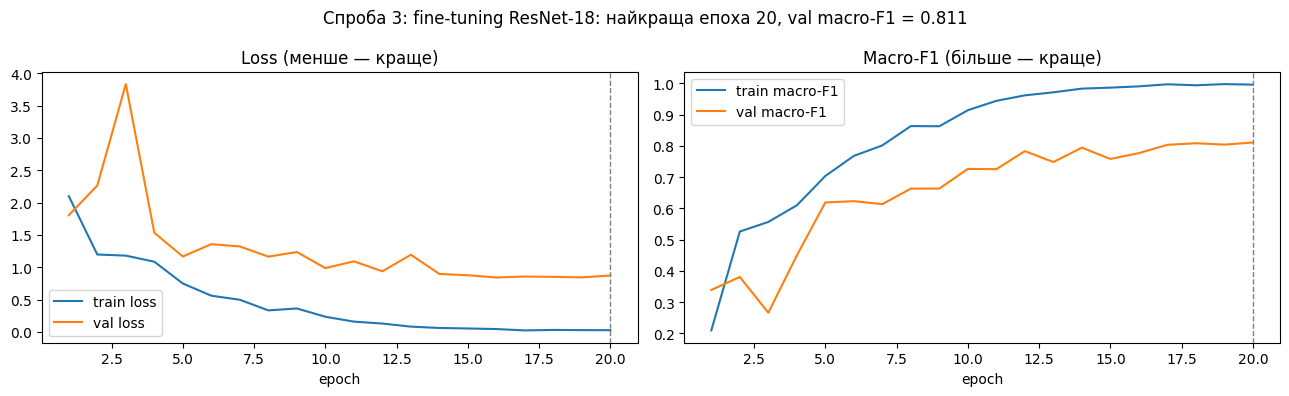

In [31]:
finetuned = fit_attempt('Спроба 3: fine-tuning ResNet-18', pretrained=True, freeze_backbone=False, lr=1e-3)

## 5. Вибір моделі та фінальна оцінка на test

Як і раніше, модель обираємо **за validation**, а test використовуємо один раз.

In [32]:
attempts = {
    'Спроба 1: заморожена ResNet-18': frozen,
    'Спроба 2: ResNet-18 з нуля': scratch,
    'Спроба 3: fine-tuning ResNet-18': finetuned,
}
summary = pd.DataFrame([
    {
        'спроба': name,
        'ваг, що навчаються': count_parameters(model, trainable_only=True),
        'найкраща епоха': int(history.loc[history['val macro-F1'].idxmax(), 'epoch']),
        'train macro-F1': history.loc[history['val macro-F1'].idxmax(), 'train macro-F1'],
        'val macro-F1': history['val macro-F1'].max(),
        'час навчання, хв': fit_cost.seconds / 60,
    }
    for name, (model, history, fit_cost) in attempts.items()
])
best_name = summary.loc[summary['val macro-F1'].idxmax(), 'спроба']
print('Обрано за validation:', best_name)
summary.round(3)

Обрано за validation: Спроба 3: fine-tuning ResNet-18


,спроба,"ваг, що навчаються",найкраща епоха,train macro-F1,val macro-F1,"час навчання, хв"
0,Спроба 1: заморожена ResNet-18,5130,10,0.643,0.500,0.370
1,Спроба 2: ResNet-18 з нуля,11181642,19,0.729,0.585,1.124
2,Спроба 3: fine-tuning ResNet-18,11181642,20,0.996,0.811,1.152


In [33]:
final_model, final_history, final_fit_cost = attempts[best_name]

with Measure() as predict_cost:
    test_pred = predict_logits(final_model, images['test']).argmax(1).cpu().numpy()

train_seconds = image_prep_cost['train'].seconds + final_fit_cost.seconds
inference_seconds = image_prep_cost['test'].seconds + predict_cost.seconds

test_accuracy = accuracy_score(y['test'], test_pred)
test_macro_f1 = f1_score(y['test'], test_pred, average='macro')

print(f'Модель: {best_name}')
print(f'Test accuracy: {test_accuracy:.3f}')
print(f'Test macro-F1: {test_macro_f1:.3f}')
print()
print(classification_report(y['test'], test_pred, target_names=classes, digits=3))

Модель: Спроба 3: fine-tuning ResNet-18
Test accuracy: 0.847
Test macro-F1: 0.848

              precision    recall  f1-score   support

    airplane      0.812     0.812     0.812        16
        bird      0.767     0.917     0.835        36
        boat      0.923     0.923     0.923        13
    building      1.000     0.912     0.954        34
         car      1.000     1.000     1.000        15
         cat      0.781     0.735     0.758        34
         dog      0.750     0.500     0.600        18
        fish      0.778     0.875     0.824         8
      flower      0.824     0.875     0.848        16
       horse      0.857     1.000     0.923        12

    accuracy                          0.847       202
   macro avg      0.849     0.855     0.848       202
weighted avg      0.848     0.847     0.843       202



**Наскільки точна ця оцінка.** Test — лише 202 рисунки, тому macro-F1 на ньому сам по собі має випадкову похибку. Оцінимо її **бутстрепом**: 2000 разів випадково вибираємо 202 рисунки з test з поверненням (деякі потрапляють двічі, деякі не потрапляють) і рахуємо macro-F1 на кожній такій вибірці. Проміжок, у який потрапляють середні 95% значень, — це 95% довірчий інтервал. Якщо його нижня межа вища за результат рівня 2, перевага рівня 3 не пояснюється випадковістю вибору test.

In [34]:
rng = np.random.default_rng(SEED)
bootstrap = []
for _ in range(2000):
    sample_idx = rng.integers(0, len(test_pred), len(test_pred))
    bootstrap.append(f1_score(y['test'][sample_idx], test_pred[sample_idx], average='macro'))
ci_low, ci_high = np.percentile(bootstrap, [2.5, 97.5])
print(f'Test macro-F1 = {test_macro_f1:.3f}, 95% довірчий інтервал: [{ci_low:.3f}, {ci_high:.3f}]')

Test macro-F1 = 0.848, 95% довірчий інтервал: [0.790, 0.891]


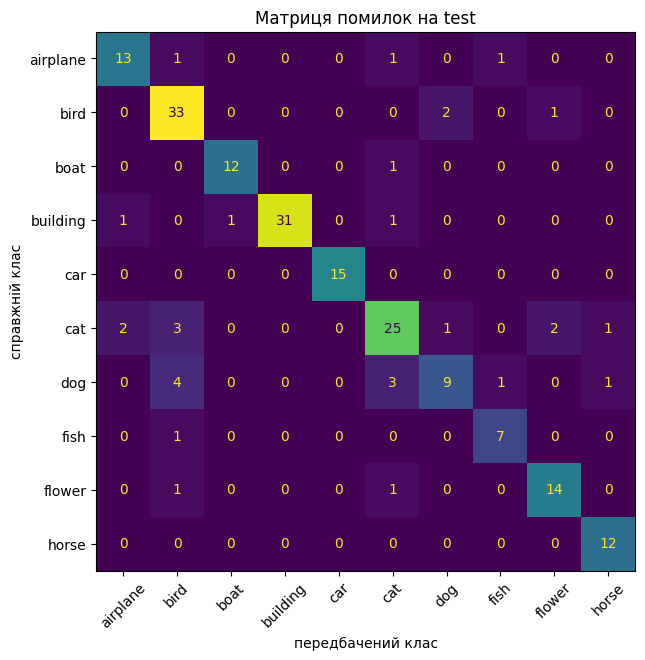

In [35]:
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(
    [classes[i] for i in y['test']], [classes[i] for i in test_pred],
    labels=classes, xticks_rotation=45, colorbar=False, ax=ax,
)
ax.set_title('Матриця помилок на test')
ax.set_xlabel('передбачений клас')
ax.set_ylabel('справжній клас')
plt.show()

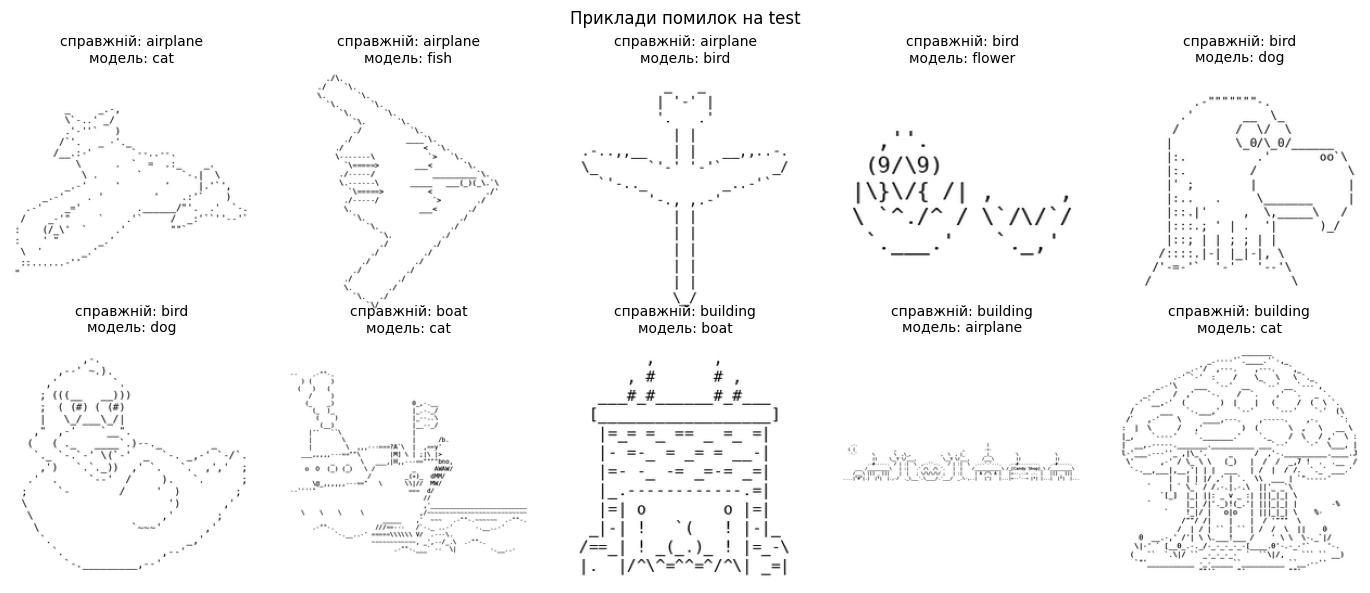

In [36]:
wrong = np.flatnonzero(test_pred != y['test'])
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for ax, i in zip(axes.flat, wrong[:10]):
    ax.imshow(images['test'][i, 0], cmap='gray_r')
    ax.set_title(f"справжній: {classes[y['test'][i]]}\nмодель: {classes[test_pred[i]]}", fontsize=10)
    ax.axis('off')
plt.suptitle('Приклади помилок на test')
plt.tight_layout()
plt.show()

**Час і пам'ять** рахуються так само, як на рівнях 1 і 2:
- **навчання** = рендер train + навчання мережі (разом з оцінкою на validation після кожної епохи). Завантаження готових ваг ImageNet у час навчання не входить: це разове скачування файлу, а не обчислення;
- **інференс** = рендер test + прохід мережі по test;
- **RAM** — пік процесу; **VRAM** — пік пам'яті GPU.

In [37]:
final_costs = [*image_prep_cost.values(), final_fit_cost, predict_cost]
vram = [m.peak_vram_mb for m in final_costs if m.peak_vram_mb is not None]

results = {
    'level': 3,
    'method': f'Transfer learning, ResNet-18 ImageNet ({best_name.split(": ")[1]})',
    'hardware': hardware,
    'test_accuracy': round(test_accuracy, 4),
    'test_macro_f1': round(test_macro_f1, 4),
    'train_seconds': round(train_seconds, 3),
    'inference_seconds': round(inference_seconds, 3),
    'inference_ms_per_sample': round(1000 * inference_seconds / len(parts['test']), 3),
    'peak_ram_mb': round(max(m.peak_mb for m in final_costs)),
    'peak_vram_mb': round(max(vram)) if vram else None,
}
with open('results.json', 'w') as f:
    json.dump(results, f, ensure_ascii=False, indent=2)
print(json.dumps(results, ensure_ascii=False, indent=2))

pd.DataFrame([
    ['Залізо', hardware],
    ['Метрика на test: accuracy', f'{test_accuracy:.3f}'],
    ['Метрика на test: macro-F1', f'{test_macro_f1:.3f} (95% ДІ {ci_low:.3f}–{ci_high:.3f})'],
    ['Час навчання: рендер train', f"{image_prep_cost['train'].seconds:.2f} с"],
    ['Час навчання: навчання мережі', f'{final_fit_cost.seconds:.1f} с ({final_fit_cost.seconds / 60:.1f} хв)'],
    ['Час навчання: разом', f'{train_seconds:.1f} с'],
    ['Час інференсу: рендер test', f"{image_prep_cost['test'].seconds:.3f} с"],
    ['Час інференсу: прохід мережі', f'{predict_cost.seconds:.3f} с'],
    ['Час інференсу: разом', f'{inference_seconds:.3f} с ({results["inference_ms_per_sample"]:.2f} мс на рисунок)'],
    ['Пікова RAM процесу', f"{results['peak_ram_mb']} MB"],
    ['Пікова VRAM', f"{results['peak_vram_mb']} MB" if vram else 'не використовується (CPU)'],
], columns=['Показник', 'Значення'])

{
  "level": 3,
  "method": "Transfer learning, ResNet-18 ImageNet (fine-tuning ResNet-18)",
  "hardware": "GPU Tesla T4",
  "test_accuracy": 0.8465,
  "test_macro_f1": 0.8478,
  "train_seconds": 85.497,
  "inference_seconds": 1.68,
  "inference_ms_per_sample": 8.317,
  "peak_ram_mb": 2312,
  "peak_vram_mb": 1711
}


,Показник,Значення
0,Залізо,GPU Tesla T4
1,Метрика на test: accuracy,0.847
2,Метрика на test: macro-F1,0.848 (95% ДІ 0.790–0.891)
3,Час навчання: рендер train,16.36 с
4,Час навчання: навчання мережі,69.1 с (1.2 хв)
5,Час навчання: разом,85.5 с
6,Час інференсу: рендер test,1.486 с
7,Час інференсу: прохід мережі,0.194 с
8,Час інференсу: разом,1.680 с (8.32 мс на рисунок)
9,Пікова RAM процесу,2312 MB


## 6. Порівняння всіх трьох рівнів

Усі рівні оцінені на тих самих 202 рисунках test. Рівень 1 рахувався на CPU ноутбука, рівні 2 і 3 — на GPU в Colab: так кожен метод використовують на практиці, і потреба в GPU — теж частина ціни методу.

In [38]:
levels = []
for path in ['../level1/results.json', '../level2/results.json']:
    with open(path) as f:
        levels.append(json.load(f))
levels[0].setdefault('hardware', 'CPU Intel(R) Core(TM) i7-8850H CPU @ 2.60GHz')

comparison = pd.DataFrame([*levels, results]).set_index('level')
comparison = comparison[['method', 'hardware', 'test_accuracy', 'test_macro_f1', 'train_seconds', 'inference_ms_per_sample', 'peak_ram_mb', 'peak_vram_mb']]
comparison.columns = ['метод', 'залізо', 'test accuracy', 'test macro-F1', 'навчання, с', 'інференс, мс/рисунок', 'пік RAM, MB', 'пік VRAM, MB']
comparison

,метод,залізо,test accuracy,test macro-F1,"навчання, с","інференс, мс/рисунок","пік RAM, MB","пік VRAM, MB"
level,,,,,,,,
1,Ручні ознаки (структурні + символи + HOG) + RF...,CPU Intel(R) Core(TM) i7-8850H CPU @ 2.60GHz,0.5149,0.5246,9.197,5.155,329,NaN
2,CNN з нуля (CNN на сітці символів),GPU Tesla T4,0.5594,0.5571,73.813,0.329,1957,612.0
3,"Transfer learning, ResNet-18 ImageNet (fine-tu...",GPU Tesla T4,0.8465,0.8478,85.497,8.317,2312,1711.0


## 7. Висновки

### Результат рівня 3

За validation обрано **повний fine-tuning ResNet-18** (спроба 3). На test він дав **macro-F1 0.848** (95% довірчий інтервал 0.790–0.891) і accuracy 0.847. Рівень 2 мав 0.557, рівень 1 — 0.525. Навіть нижня межа довірчого інтервалу (0.790) значно вища за результат рівня 2. На відміну від рівня 2, де приріст був у межах випадкових коливань, тут перевага не пояснюється випадковістю вибору test: це справді помітний крок уперед.

**Що показали три спроби:**
- **Заморожена мережа** (навчається лише останній шар) дала на validation лише 0.500, тобто приблизно рівень 1 і 2. Ознаки з ImageNet самі по собі не дуже підходять: вони навчені на фотографіях, а не на рисунках із символів.
- **ResNet-18 з випадковими вагами** дала 0.585. Це трохи краще за CNN рівня 2 (0.522), але далеко від fine-tuning. Її val-криві нестабільні, а за 20 епох вона ще не досягла свого максимуму. Але той самий бюджет fine-tuning використав значно ефективніше.
- **Fine-tuning** дав 0.811 на validation. Архітектура та сама, що в спробі 2, а різниця лише в початкових вагах. Отже, головний внесок дає саме **передобучення**, а не розмір мережі. Водночас воно працює лише тоді, коли мережу підлаштовують під наші дані, як показує спроба 1.

**По класах.** car (F1 1.000), building (0.954), boat і horse (0.923) розпізнаються майже без помилок. Клас cat, найслабший на рівні 2 (0.275), піднявся до 0.758. Найслабшим залишається **dog** (0.600): з 18 собак у test правильно розпізнано 9, а 7 модель прийняла за птахів або котів. Собак, котів і птахів в ASCII-арті часто малюють схожими «мордочками», а самі собаки в датасеті дуже різноманітні.

**Перенавчання.** Train macro-F1 доходить до ≈ 1.0, а val — до 0.81, тобто модель запам'ятовує train повністю. Але val при цьому не падає, а повільно росте до кінця навчання: передобучені ваги, аугментація, weight decay і вибір найкращої епохи за validation стримують перенавчання, тому воно не шкодить якості на нових даних.

### Ціна

- **Навчання:** 85.5 с на GPU Tesla T4, з них 69 с — сама мережа і 16 с — рендер рисунків 224×224 на CPU. Це порівнянно з рівнем 2 (74 с), але на CPU ноутбука це тривало б понад годину. Окрема прихована ціна — передобучення на ImageNet: його вже хтось заплатив за нас, витративши дні роботи кількох GPU.
- **Пам'ять:** 2312 MB RAM і 1711 MB VRAM — найбільше з трьох рівнів. Сама модель займає ≈ 45 MB (11.2 млн ваг), проти ≈ 0.4 MB у рівня 2.
- **Інференс:** 8.3 мс на рисунок, з них ≈ 88% — рендер у зображення 224×224. Сама мережа обробляє рисунок менш ніж за 1 мс на GPU. Рівень 2 був швидшим (0.33 мс), бо сітка символів будується з тексту майже миттєво.

### Порівняння рівнів і коли обирати простіший метод

| | Рівень 1 | Рівень 2 | Рівень 3 |
|---|---|---|---|
| Метод | ручні ознаки + Random Forest | CNN з нуля | fine-tuning ResNet-18 |
| Test macro-F1 | 0.525 | 0.557 | **0.848** |
| Потрібен GPU | ні | так, для навчання | так, для навчання |
| Навчання | 9 с на CPU | 74 с на GPU | 86 с на GPU |
| Складність | найпростіший | власна архітектура | готова модель, але важка |

1. **Рівень 1 (класичний ML)** варто обирати, коли немає GPU, потрібне швидке навчання і простий запуск, важлива зрозумілість ознак або потрібна швидка базова модель. На наших даних він дав 0.525 за 9 секунд на звичайному процесорі. Крім того, саме він показав, у що впирається задача: ручні ознаки не розрізняють схожих тварин.
2. **Рівень 2 (DL з нуля)** на наших даних виявився найгіршим компромісом: +0.03 macro-F1 (у межах шуму) за ціною GPU, у 6 разів більшої пам'яті і складнішого коду. Навчання з нуля виправдане, коли даних багато (десятки тисяч прикладів і більше) або коли для типу даних немає відповідної передобученої моделі.
3. **Рівень 3 (fine-tuning)** виправданий, коли важлива якість і існує передобучена модель на схожих даних (тут — зображеннях). Він дав приріст +0.29 macro-F1 при тому самому обсязі даних. Ціна — GPU для навчання, більше пам'яті й залежність від чужої моделі.

**Загальне правило, яке підтвердила ця лабораторна:** починати треба з простого методу як базового рівня і переходити до складнішого лише тоді, коли приріст якості більший за випадкові коливання (тут — довірчий інтервал на test) і виправдовує додаткову ціну. Для малого датасету складніший метод допомагає не сам по собі: рівень 2 майже нічого не дав. Допомагає лише той, що приносить знання ззовні, тобто передобучення на великих даних.